PART A: Simple linear regression from scratch
Gradient descent : slope = 2.7701, intercept = 7.2151
Normal equation  : slope = 2.7701, intercept = 7.2151
True values      : slope = 3.0000, intercept = 7.0000


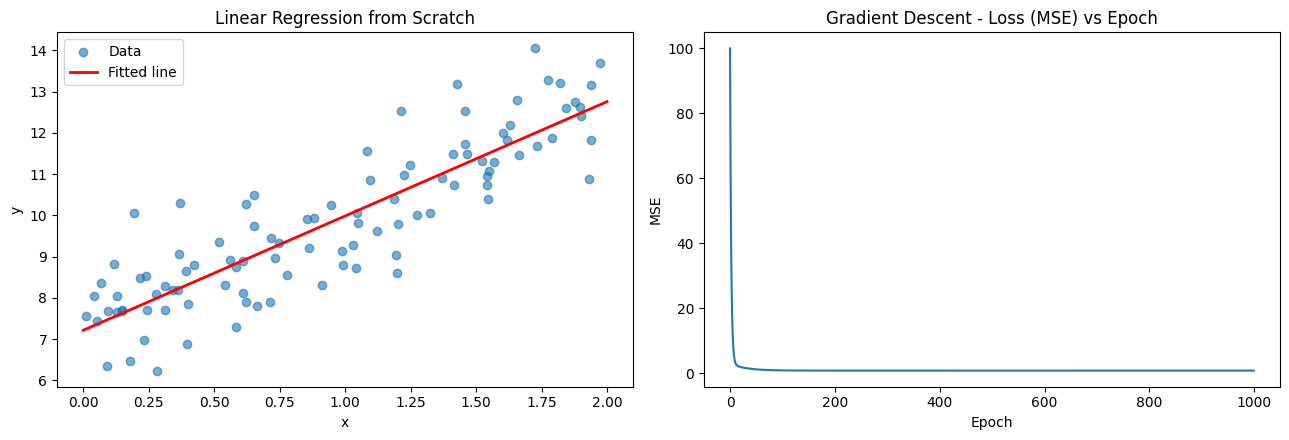


PART B: Simple linear regression with scikit-learn
Equation: target = 998.58 * bmi + 152.00
R^2 : 0.2334


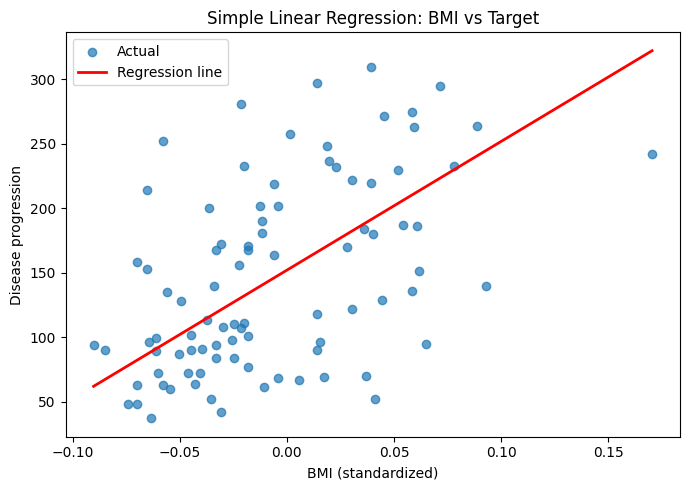


PART C: Multiple linear regression (all 10 features)
Intercept: 151.346
feature  coefficient
     s1     -931.489
     s5      736.199
    bmi      542.429
     s2      518.062
     bp      347.704
     s4      275.318
    sex     -241.964
     s3      163.420
     s6       48.671
    age       37.904

PART D: Evaluation metrics
MAE         : 42.794
MSE         : 2900.194
RMSE        : 53.853
R^2         : 0.4526
Adjusted R^2: 0.3824
5-fold CV R^2: 0.4823 (+/- 0.0493)


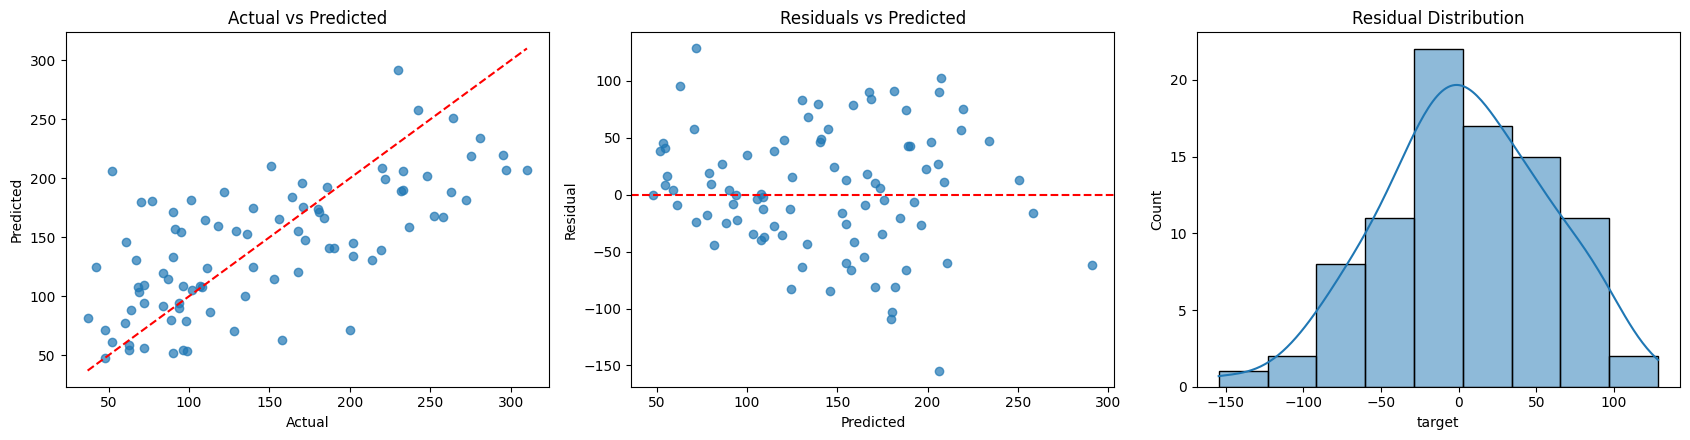

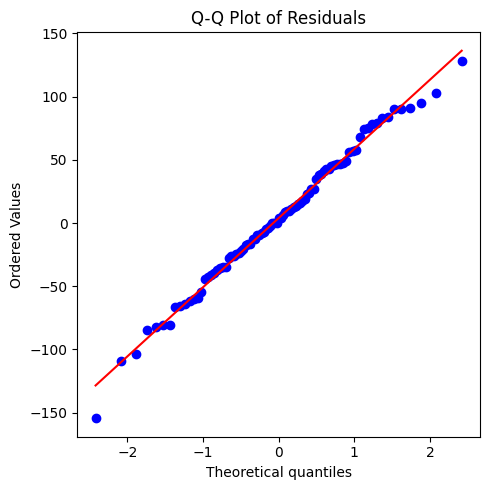


Conclusion: Linear regression fits y = w1*x1 + ... + wn*xn + b by minimizing squared error. Gradient descent and the normal equation give the same answer; R^2 shows how much variance the model explains.


In [ ]:
"""
Assignment 6: Implement Linear Regression Algorithm.

Parts:
  A. Simple linear regression from scratch (gradient descent + closed form)
  B. Simple linear regression with scikit-learn
  C. Multiple linear regression (Diabetes dataset)
  D. Evaluation metrics and residual analysis

Install: pip install numpy pandas matplotlib seaborn scikit-learn scipy
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

np.random.seed(42)

# ==================================================================
# PART A: Simple Linear Regression FROM SCRATCH
#         Model: y = w*x + b
# ==================================================================
print("=" * 60)
print("PART A: Simple linear regression from scratch")
print("=" * 60)

# Synthetic data: true relation y = 3x + 7 + noise
X_syn = 2 * np.random.rand(100, 1)
y_syn = 3 * X_syn[:, 0] + 7 + np.random.randn(100)


class LinearRegressionScratch:
    """Linear regression trained with batch gradient descent."""

    def __init__(self, lr=0.05, epochs=1000):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        n, m = X.shape
        self.w = np.zeros(m)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.epochs):
            y_hat = X @ self.w + self.b
            error = y_hat - y

            # gradients of MSE = (1/n) * sum((y_hat - y)^2)
            dw = (2 / n) * (X.T @ error)
            db = (2 / n) * error.sum()

            self.w -= self.lr * dw
            self.b -= self.lr * db
            self.loss_history.append(np.mean(error ** 2))
        return self

    def predict(self, X):
        return X @ self.w + self.b


gd_model = LinearRegressionScratch(lr=0.05, epochs=1000).fit(X_syn, y_syn)
print(f"Gradient descent : slope = {gd_model.w[0]:.4f}, intercept = {gd_model.b:.4f}")

# Closed-form solution (Normal Equation): theta = (X^T X)^-1 X^T y
X_b = np.c_[np.ones(len(X_syn)), X_syn]
theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y_syn
print(f"Normal equation  : slope = {theta[1]:.4f}, intercept = {theta[0]:.4f}")
print("True values      : slope = 3.0000, intercept = 7.0000")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(X_syn, y_syn, alpha=0.6, label="Data")
x_line = np.linspace(0, 2, 100).reshape(-1, 1)
ax[0].plot(x_line, gd_model.predict(x_line), "r", linewidth=2, label="Fitted line")
ax[0].set_title("Linear Regression from Scratch")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].legend()

ax[1].plot(gd_model.loss_history)
ax[1].set_title("Gradient Descent - Loss (MSE) vs Epoch")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("MSE")
plt.tight_layout()
plt.show()

# ==================================================================
# PART B: Simple Linear Regression with scikit-learn
# ==================================================================
print("\n" + "=" * 60)
print("PART B: Simple linear regression with scikit-learn")
print("=" * 60)

diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

# Use a single feature (BMI) to predict disease progression
X_single = df[["bmi"]]
y = df["target"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_single, y, test_size=0.2, random_state=42)

simple = LinearRegression().fit(Xs_train, ys_train)
ys_pred = simple.predict(Xs_test)

print(f"Equation: target = {simple.coef_[0]:.2f} * bmi + {simple.intercept_:.2f}")
print(f"R^2 : {r2_score(ys_test, ys_pred):.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(Xs_test, ys_test, alpha=0.7, label="Actual")
plt.plot(Xs_test.sort_values("bmi"),
         simple.predict(Xs_test.sort_values("bmi")),
         color="red", linewidth=2, label="Regression line")
plt.xlabel("BMI (standardized)")
plt.ylabel("Disease progression")
plt.title("Simple Linear Regression: BMI vs Target")
plt.legend()
plt.tight_layout()
plt.show()

# ==================================================================
# PART C: Multiple Linear Regression
# ==================================================================
print("\n" + "=" * 60)
print("PART C: Multiple linear regression (all 10 features)")
print("=" * 60)

X = df.drop(columns="target")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

multi = LinearRegression().fit(X_train, y_train)
y_pred = multi.predict(X_test)

coef = pd.DataFrame({"feature": X.columns, "coefficient": multi.coef_})
print("Intercept:", round(multi.intercept_, 3))
print(coef.sort_values("coefficient", key=abs, ascending=False)
      .round(3).to_string(index=False))

# ==================================================================
# PART D: Evaluation and residual analysis
# ==================================================================
print("\n" + "=" * 60)
print("PART D: Evaluation metrics")
print("=" * 60)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"MAE         : {mae:.3f}")
print(f"MSE         : {mse:.3f}")
print(f"RMSE        : {rmse:.3f}")
print(f"R^2         : {r2:.4f}")
print(f"Adjusted R^2: {adj_r2:.4f}")

cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print(f"5-fold CV R^2: {cv.mean():.4f} (+/- {cv.std():.4f})")

residuals = y_test - y_pred

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].scatter(y_test, y_pred, alpha=0.7)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--")
ax[0].set_title("Actual vs Predicted")
ax[0].set_xlabel("Actual")
ax[0].set_ylabel("Predicted")

ax[1].scatter(y_pred, residuals, alpha=0.7)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_title("Residuals vs Predicted")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Residual")

sns.histplot(residuals, kde=True, ax=ax[2])
ax[2].set_title("Residual Distribution")
plt.tight_layout()
plt.show()

# Normality of residuals (Q-Q plot) - one of the regression assumptions
plt.figure(figsize=(5, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.tight_layout()
plt.show()

print("\nConclusion: Linear regression fits y = w1*x1 + ... + wn*xn + b by "
      "minimizing squared error. Gradient descent and the normal equation "
      "give the same answer; R^2 shows how much variance the model explains.")